# Lab 8 — Experiment notebook

**This notebook is a working tool, not a deliverable — you do NOT submit it.**

It contains no logic of its own: it imports your finished functions from `../src/lab08.py`
and plots their output. If a cell below fails, the bug is in your `.py`, not in the plot.

Your job: complete the three plot cells, then **export each figure and paste it into
`report.pdf`** (right-click -> Save image as..., or `plt.savefig('fig1.png', dpi=150)`).
Report figures 1-3 are required by the report template.


In [8]:
import sys
sys.path.insert(0, '../src')
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import lab08

X, y, groups = lab08.load_data('../data/delivery_late.csv')
data = (X, y, groups)

table = lab08.run_ablation(lab08.BASE_CONFIG, lab08.FACTORS, lab08.SEEDS, data=data)
ablation = table.groupby('variant', sort=False)['f1'].agg(['mean', 'std']).round(4)

y_val, y_pred, groups_val = lab08.base_predictions(lab08.SEED)
errors = lab08.error_analysis(y_val, y_pred, groups_val)

records = [lab08.run_config(cfg, seed, data=data)
           for cfg in (lab08.BASE_CONFIG, lab08.CHALLENGER_CONFIG)
           for seed in lab08.SEEDS]
ranking = lab08.summarize(records)
ablation


,mean,std
variant,,
base,0.6439,0.0230
features=with_region,0.7355,0.0270
features=core,0.4741,0.0302
model=tree,0.5292,0.0431
class_weight=balanced,0.6787,0.0180
scale=False,0.6358,0.0210


## Plot 1 — Overall accuracy against per-slice accuracy

The point of the figure is the distance between the overall line and the worst bar, and the
sample count printed on each bar. A slice with fewer than 30 samples is not evidence.


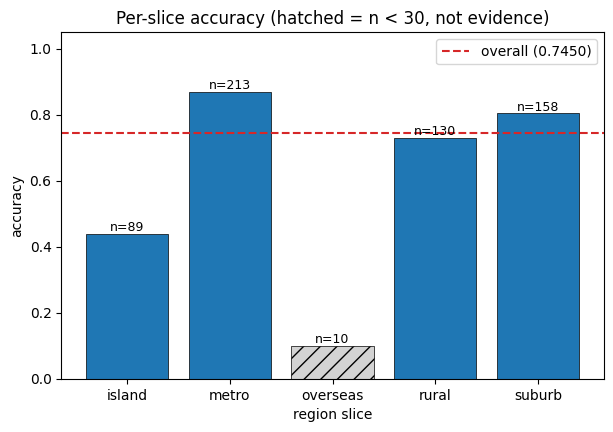

In [9]:
# ============ TODO (Plot 1) ============
# Bar chart of accuracy per slice from `errors["slices"]`, one bar per region.
# Draw the overall accuracy as a horizontal line, and print n on top of each bar.
# Mark (hatch, or a lighter colour) the slices with n < 30.
# =======================================
labels = list(errors['slices'])
acc = [errors['slices'][k]['accuracy'] for k in labels]
ns = [errors['slices'][k]['n'] for k in labels]
colors = ['tab:blue' if n >= 30 else 'lightgray' for n in ns]

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(labels, acc, color=colors, edgecolor='black', linewidth=0.5)
for b, n in zip(bars, ns):
    if n < 30:
        b.set_hatch('//')
    ax.text(b.get_x()+b.get_width()/2, b.get_height(), f'n={n}',
            ha='center', va='bottom', fontsize=9)
ax.axhline(errors['overall']['accuracy'], linestyle='--', color='tab:red',
           label=f"overall ({errors['overall']['accuracy']:.4f})")
ax.set_ylabel('accuracy')
ax.set_xlabel('region slice')
ax.set_ylim(0, 1.05)
ax.set_title('Per-slice accuracy (hatched = n < 30, not evidence)')
ax.legend()
plt.savefig('fig1.png', dpi=150, bbox_inches='tight')
plt.show()


## Plot 2 — Ablation: which factors clear the seed noise

Each variant differs from the base in exactly one factor. The error bar is one sample standard
deviation over `lab08.SEEDS`. A bar whose error bar reaches the base band has not been shown to
do anything.


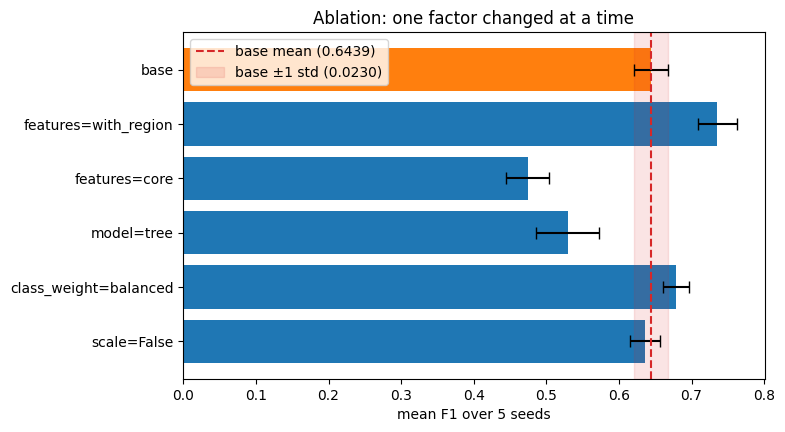

In [10]:
# ============ TODO (Plot 2) ============
# Horizontal bar chart of mean F1 per variant from `ablation`, with +-1 std error bars.
# Draw the base mean as a vertical line and its +-1 std as a shaded band.
# =======================================
order = list(ablation.index)[::-1]
means = ablation.loc[order, 'mean'].to_numpy()
stds = ablation.loc[order, 'std'].to_numpy()
base_mean = ablation.loc['base', 'mean']
base_std = ablation.loc['base', 'std']

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.barh(order, means, xerr=stds, capsize=4,
        color=['tab:orange' if v == 'base' else 'tab:blue' for v in order])
ax.axvline(base_mean, color='tab:red', linestyle='--', label=f'base mean ({base_mean:.4f})')
ax.axvspan(base_mean-base_std, base_mean+base_std, color='tab:red', alpha=0.12,
           label=f'base ±1 std ({base_std:.4f})')
ax.set_xlabel('mean F1 over 5 seeds')
ax.set_title('Ablation: one factor changed at a time')
ax.legend(loc='upper left')
plt.savefig('fig2.png', dpi=150, bbox_inches='tight')
plt.show()


## Plot 3 — Seed spread of two configurations

Same data as `ranking`, but one point per seed instead of one number per configuration. If the
two clouds interleave, the ranking between them is not a result yet.


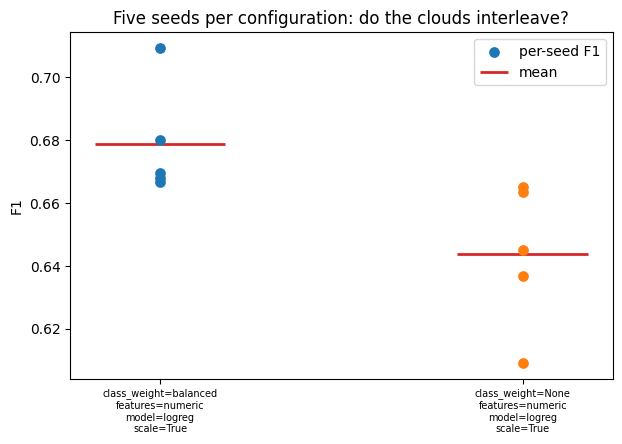

In [11]:
# ============ TODO (Plot 3) ============
# One point per (configuration, seed) for the base and the challenger, using `records`.
# Put the mean as a longer marker or a line. Label the axis with the metric name.
# =======================================

ids = list(ranking['config_id'])
fig, ax = plt.subplots(figsize=(7, 4.5))
for i, cid in enumerate(ids):
    vals = [r['metrics']['f1'] for r in records if r['config_id'] == cid]
    ax.scatter([i]*len(vals), vals, s=45, zorder=3,
               label='per-seed F1' if i == 0 else None)
    ax.hlines(np.mean(vals), i-0.18, i+0.18, color='tab:red', linewidth=2,
              label='mean' if i == 0 else None)
ax.set_xticks(range(len(ids)))
ax.set_xticklabels([c.replace('|', '\n') for c in ids], fontsize=7)
ax.set_ylabel('F1')
ax.set_title('Five seeds per configuration: do the clouds interleave?')
ax.legend()
plt.savefig('fig3.png', dpi=150, bbox_inches='tight')
plt.show()